In [4]:
import numpy as np
import os
import json
import pandas as pd
import math 
from pyscf import scf

import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Times New Roman"]
plt.rcParams['font.size'] = 14

In [5]:
cwd = os.getcwd()
file_names = [f for f in os.listdir(cwd) if f.startswith("cc-")]

# 1. Load data

In [6]:
full_dataset = dict()
for basis in file_names:

    full_dataset[basis] = dict() 

    basis_dir = os.path.join(cwd, basis)

    metadata_file = os.path.join(basis_dir, f'metadata_{basis}.json')
    with open(metadata_file, "r") as infile0:
        meta_data = json.load(infile0)

    QUBO_dir = os.path.join(basis_dir, "QUBO")

    e_list_new         = []
    e_list_new_so      = []
    e_list_pyscf       = []
    e_list_pyscf_so    = []
    init_list          = []
    init_list_so       = []
    conv_list_pyscf    = []
    conv_list_pyscf_so = []
    internal_stability_list_pyscf    = []
    internal_stability_list_pyscf_so    = []


    files = sorted([ff for ff in os.listdir(QUBO_dir) if ff.endswith(".json")])
    for qubo_file in files:
        init_strat, scf_type = qubo_file.split("_")[2:4]
        scf_type = scf_type.split(".")[0]
        pyscf_file = os.path.join(basis_dir, f"{basis}_{init_strat}_{scf_type}.chk")

        mol = scf.chkfile.load_mol(pyscf_file)
        rohf_obj = scf.ROHF(mol) 
        rohf_obj.__dict__.update(scf.chkfile.load(pyscf_file, "scf"))

        with open(os.path.join(QUBO_dir, qubo_file), "r") as infile:
            qubo_data = json.load(infile)

        pyscf_e      = qubo_data["pyscf_e"]
        psi_pyscf    = np.array(qubo_data["pyscf_psi"], dtype=np.int8)

        e_soln_1     = qubo_data["e_soln_1"]
        state_soln_1 = np.array(qubo_data["state_soln_1"], dtype=np.int8)

        Q_mat        = np.array(qubo_data["Q_mat"])
        Q_const      = qubo_data["Q_const"]

        interal_stab = meta_data[init_strat][scf_type]['internal_stability']
        scf_converg  = meta_data[init_strat][scf_type]['has_converged']
        
        assert np.isclose(pyscf_e, np.einsum("i,ij,j", psi_pyscf,Q_mat,psi_pyscf)+ Q_const)
        assert np.isclose(e_soln_1, np.einsum("i,ij,j", state_soln_1,Q_mat,state_soln_1)+ Q_const)
        assert np.isclose(rohf_obj.e_tot, pyscf_e)

        assert qubo_data["spin"] == np.logical_xor(psi_pyscf[0::2], psi_pyscf[1::2]).sum()
        assert qubo_data["spin"] == np.logical_xor(state_soln_1[0::2], state_soln_1[1::2]).sum()

        assert np.allclose(qubo_data["nelec"], (psi_pyscf[0::2].sum(), psi_pyscf[1::2].sum()))
        assert np.allclose(qubo_data["nelec"], (state_soln_1[0::2].sum(), state_soln_1[1::2].sum()))

        if scf_type == "rohf":
            e_list_new.append(e_soln_1)
            e_list_pyscf.append(pyscf_e)
            init_list.append(init_strat)
            conv_list_pyscf.append(scf_converg)
            internal_stability_list_pyscf.append(interal_stab)
        else:
            e_list_new_so.append(e_soln_1)
            e_list_pyscf_so.append(pyscf_e)
            init_list_so.append(init_strat)
            conv_list_pyscf_so.append(scf_converg)
            internal_stability_list_pyscf_so.append(interal_stab)

    full_dataset[basis] = {"rohf": {"e_new": e_list_new,
                                    "e_pyscf": e_list_pyscf,
                                    "init": init_list,
                                    "conv": conv_list_pyscf,
                                    "stab": internal_stability_list_pyscf},
                           "rohf-so": {"e_new": e_list_new_so,
                                    "e_pyscf": e_list_pyscf_so,
                                    "init": init_list_so,
                                    "conv": conv_list_pyscf_so,
                                    "stab": internal_stability_list_pyscf_so},
                            }

In [7]:
DZ_e_new_list   = np.array(full_dataset['cc-pVDZ']["rohf"]['e_new'])
DZ_e_pyscf_list = np.array(full_dataset['cc-pVDZ']["rohf"]['e_pyscf'])
DZ_init_list    = np.array(full_dataset['cc-pVDZ']["rohf"]['init'])
DZ_conv_list    = np.array(full_dataset['cc-pVDZ']["rohf"]['conv'])
DZ_stab_list    = np.array(full_dataset['cc-pVDZ']["rohf"]['stab'])

DZ_SO_e_new_list   = np.array(full_dataset['cc-pVDZ']["rohf-so"]['e_new'])
DZ_SO_e_pyscf_list = np.array(full_dataset['cc-pVDZ']["rohf-so"]['e_pyscf'])
DZ_SO_init_list    = np.array(full_dataset['cc-pVDZ']["rohf-so"]['init'])
DZ_SO_conv_list    = np.array(full_dataset['cc-pVDZ']["rohf-so"]['conv'])
DZ_SO_stab_list    = np.array(full_dataset['cc-pVDZ']["rohf-so"]['stab'])

DT_e_new_list   = np.array(full_dataset['cc-pVTZ']["rohf"]['e_new'])
DT_e_pyscf_list = np.array(full_dataset['cc-pVTZ']["rohf"]['e_pyscf'])
DT_init_list    = np.array(full_dataset['cc-pVTZ']["rohf"]['init'])
DT_conv_list    = np.array(full_dataset['cc-pVTZ']["rohf"]['conv'])
DT_stab_list    = np.array(full_dataset['cc-pVTZ']["rohf"]['stab'])

DT_SO_e_new_list   = np.array(full_dataset['cc-pVTZ']["rohf-so"]['e_new'])
DT_SO_e_pyscf_list = np.array(full_dataset['cc-pVTZ']["rohf-so"]['e_pyscf'])
DT_SO_init_list    = np.array(full_dataset['cc-pVTZ']["rohf-so"]['init'])
DT_SO_conv_list    = np.array(full_dataset['cc-pVTZ']["rohf-so"]['conv'])
DT_SO_stab_list    = np.array(full_dataset['cc-pVTZ']["rohf-so"]['stab'])


DQ_e_new_list   = np.array(full_dataset['cc-pVQZ']["rohf"]['e_new'])
DQ_e_pyscf_list = np.array(full_dataset['cc-pVQZ']["rohf"]['e_pyscf'])
DQ_init_list    = np.array(full_dataset['cc-pVQZ']["rohf"]['init'])
DQ_conv_list    = np.array(full_dataset['cc-pVQZ']["rohf"]['conv'])
DQ_stab_list    = np.array(full_dataset['cc-pVQZ']["rohf"]['stab'])

DQ_SO_e_new_list   = np.array(full_dataset['cc-pVQZ']["rohf-so"]['e_new'])
DQ_SO_e_pyscf_list = np.array(full_dataset['cc-pVQZ']["rohf-so"]['e_pyscf'])
DQ_SO_init_list    = np.array(full_dataset['cc-pVQZ']["rohf-so"]['init'])
DQ_SO_conv_list    = np.array(full_dataset['cc-pVQZ']["rohf-so"]['conv'])
DQ_SO_stab_list    = np.array(full_dataset['cc-pVQZ']["rohf-so"]['stab'])


In [8]:
## use a shift to make the plot more readable
shift = 223

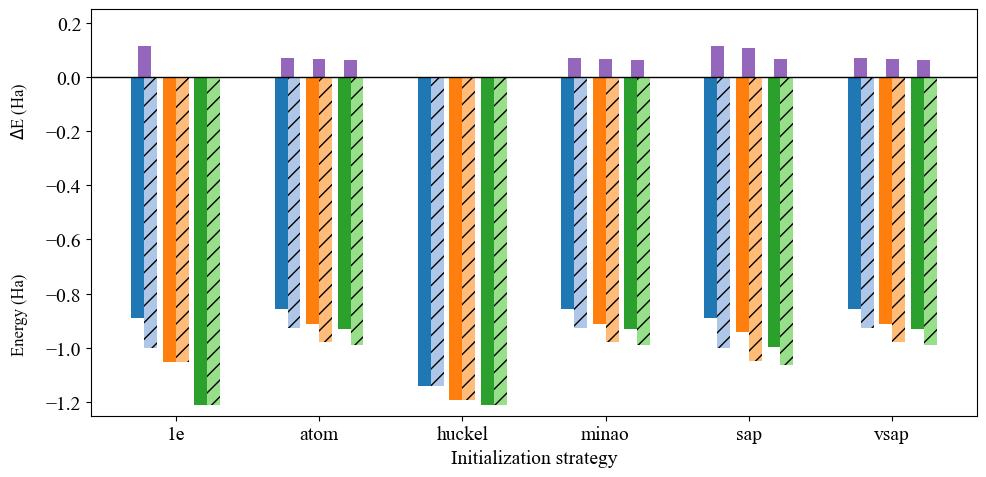

In [9]:
## plot data

assert np.all(DZ_init_list == DT_init_list) and np.all(DZ_init_list == DQ_init_list)  
labels = DZ_init_list
x = np.arange(len(labels))

width = 0.09
pair_gap = 0.04

pair_spacing = 2 * width + pair_gap
pair_centers = np.array([
    -pair_spacing,
    0,
    pair_spacing
])

# Original data
pairs = [
    (DZ_e_pyscf_list + shift, DZ_e_new_list + shift),
    (DT_e_pyscf_list + shift, DT_e_new_list + shift),
    (DQ_e_pyscf_list + shift, DQ_e_new_list + shift),
]

colors = [
    ('#1f77b4', '#aec7e8'),
    ('#ff7f0e', '#ffbb78'),
    ('#2ca02c', '#98df8a')
]

fig, ax = plt.subplots(figsize=(10, 5))

for center, (c1, c2), (y1, y2) in zip(pair_centers, colors, pairs):

    # Bottom: original values plotted downward
    ax.bar(
        x + center - width/2,
        y1,
        width,
        color=c1
    )

    ax.bar(
        x + center + width/2,
        y2,
        width,
        color=c2,
        hatch='//'
    )

    # Top: difference between a pair
    diff = np.abs(y2 - y1)

    ax.bar(
        x + center,
        diff,
        width,
        color='#9467bd',
    )

# zero line
ax.axhline(0, color='black', linewidth=1)

ax.set_xticks(x)
ax.set_xticklabels(labels)

# ax.set_ylabel("Energy (Ha)")
# Add region labels
ax.text(
    -0.08, 0.75, r"$\Delta$E (Ha)",
    transform=ax.transAxes,
    rotation=90,
    va='center',
    ha='center',
    # color='#9467bd',
    color="black",
    fontsize=12
)

ax.text(
    -0.08, 0.25, "Energy (Ha)",
    transform=ax.transAxes,
    rotation=90,
    va='center',
    ha='center',
    color='black',
    fontsize=12
)


ax.set_ylim(-1.25, 0.25)
ax.set_xlabel("Initialization strategy")

plt.tight_layout()
fig.savefig('O3-results.png', dpi=300)
plt.show()

In [10]:
## use a shift to make the plot more readable
shift = 222

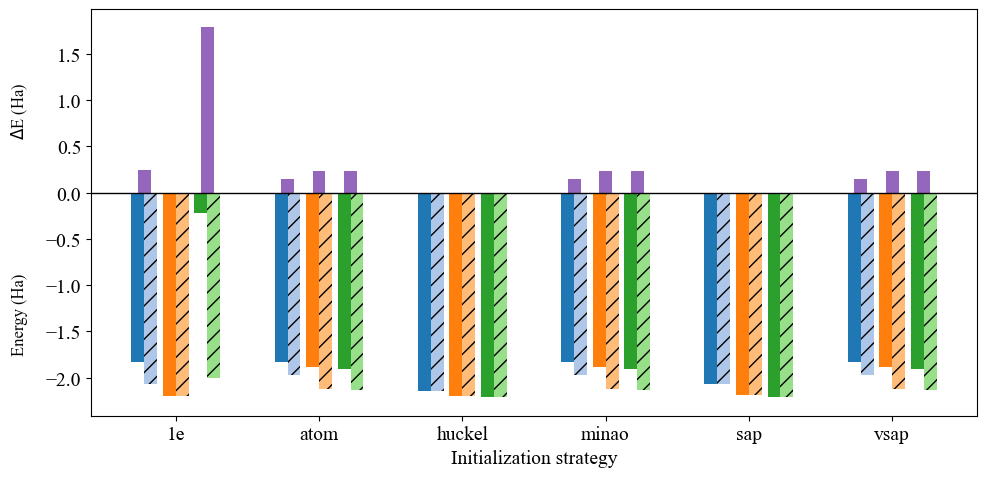

In [11]:
assert np.all(DZ_SO_init_list == DT_SO_init_list) and np.all(DZ_SO_init_list == DQ_SO_init_list)  
labels = DZ_init_list
x = np.arange(len(labels))

width = 0.09
pair_gap = 0.04

pair_spacing = 2 * width + pair_gap
pair_centers = np.array([
    -pair_spacing,
    0,
    pair_spacing
])

# Original data
pairs = [
    (DZ_SO_e_pyscf_list + shift, DZ_SO_e_new_list + shift),
    (DT_SO_e_pyscf_list + shift, DT_SO_e_new_list + shift),
    (DQ_SO_e_pyscf_list + shift, DQ_SO_e_new_list + shift),
]

colors = [
    ('#1f77b4', '#aec7e8'),
    ('#ff7f0e', '#ffbb78'),
    ('#2ca02c', '#98df8a')
]

fig, ax = plt.subplots(figsize=(10, 5))

for center, (c1, c2), (y1, y2) in zip(pair_centers, colors, pairs):

    # Bottom: original values plotted downward
    ax.bar(
        x + center - width/2,
        y1,
        width,
        color=c1
    )

    ax.bar(
        x + center + width/2,
        y2,
        width,
        color=c2,
        hatch='//'
    )

    # Top: difference between a pair
    diff = np.abs(y2 - y1)

    ax.bar(
        x + center,
        diff,
        width,
        color='#9467bd',
    )

# zero line
ax.axhline(0, color='black', linewidth=1)

ax.set_xticks(x)
ax.set_xticklabels(labels)

# ax.set_ylabel("Energy (Ha)")
# Add region labels
ax.text(
    -0.08, 0.75, r"$\Delta$E (Ha)",
    transform=ax.transAxes,
    rotation=90,
    va='center',
    ha='center',
    # color='#9467bd',
    color="black",
    fontsize=12
)

ax.text(
    -0.08, 0.25, "Energy (Ha)",
    transform=ax.transAxes,
    rotation=90,
    va='center',
    ha='center',
    color='black',
    fontsize=12
)


ax.set_xlabel("Initialization strategy")

plt.tight_layout()

fig.savefig('O3-results-SO.png', dpi=300)
plt.show()

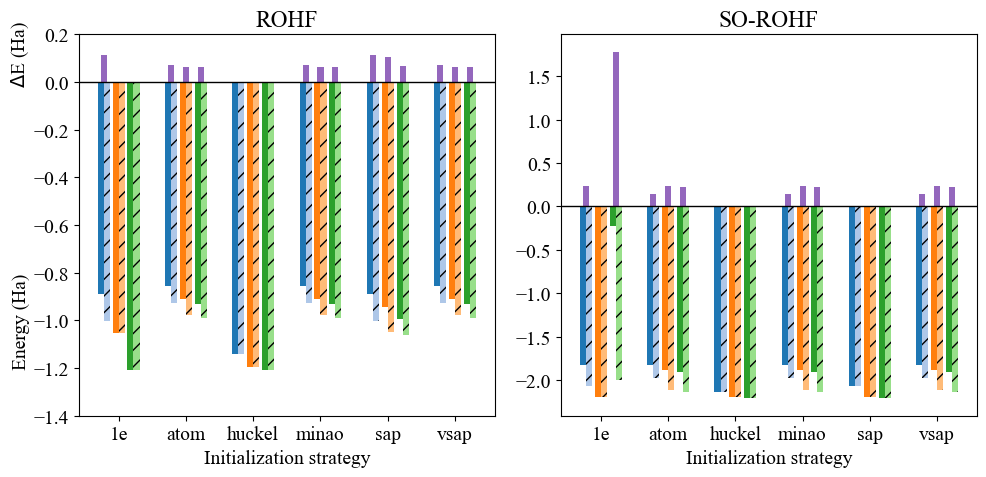

In [12]:
shift1 = 223
shift2 = 222

## combined
fig, (ax1, ax2) = plt.subplots(1, 2, sharey=False, figsize=(10, 5))

## plot data

assert np.all(DZ_init_list == DT_init_list) and np.all(DZ_init_list == DQ_init_list)  
labels = DZ_init_list
x = np.arange(len(labels))

width = 0.09
pair_gap = 0.04

pair_spacing = 2 * width + pair_gap
pair_centers = np.array([
    -pair_spacing,
    0,
    pair_spacing
])

# Original data
pairs = [
    (DZ_e_pyscf_list + shift1, DZ_e_new_list + shift1),
    (DT_e_pyscf_list + shift1, DT_e_new_list + shift1),
    (DQ_e_pyscf_list + shift1, DQ_e_new_list + shift1),
]

colors = [
    ('#1f77b4', '#aec7e8'),
    ('#ff7f0e', '#ffbb78'),
    ('#2ca02c', '#98df8a')
]

for center, (c1, c2), (y1, y2) in zip(pair_centers, colors, pairs):

    # Bottom: original values plotted downward
    ax1.bar(
        x + center - width/2,
        y1,
        width,
        color=c1
    )

    ax1.bar(
        x + center + width/2,
        y2,
        width,
        color=c2,
        hatch='//'
    )

    # Top: difference between a pair
    diff = np.abs(y2 - y1)

    ax1.bar(
        x + center,
        diff,
        width,
        color='#9467bd',
    )

# zero line
ax1.axhline(0, color='black', linewidth=1)

ax1.set_xticks(x)
ax1.set_xticklabels(labels)

ax1.set_xlabel("Initialization strategy")



assert np.all(DZ_SO_init_list == DT_SO_init_list) and np.all(DZ_SO_init_list == DQ_SO_init_list)  
labels = DZ_init_list
x = np.arange(len(labels))

width = 0.09
pair_gap = 0.04

pair_spacing = 2 * width + pair_gap
pair_centers = np.array([
    -pair_spacing,
    0,
    pair_spacing
])

# Original data
pairs = [
    (DZ_SO_e_pyscf_list + shift2, DZ_SO_e_new_list + shift2),
    (DT_SO_e_pyscf_list + shift2, DT_SO_e_new_list + shift2),
    (DQ_SO_e_pyscf_list + shift2, DQ_SO_e_new_list + shift2),
]

colors = [
    ('#1f77b4', '#aec7e8'),
    ('#ff7f0e', '#ffbb78'),
    ('#2ca02c', '#98df8a')
]

for center, (c1, c2), (y1, y2) in zip(pair_centers, colors, pairs):

    # Bottom: original values plotted downward
    ax2.bar(
        x + center - width/2,
        y1,
        width,
        color=c1
    )

    ax2.bar(
        x + center + width/2,
        y2,
        width,
        color=c2,
        hatch='//'
    )

    # Top: difference between a pair
    diff = np.abs(y2 - y1)

    ax2.bar(
        x + center,
        diff,
        width,
        color='#9467bd',
    )

# zero line
ax2.axhline(0, color='black', linewidth=1)

ax2.set_xticks(x)
ax2.set_xticklabels(labels)
ax2.set_xlabel("Initialization strategy")



## plot double y labels
ax1.text(
    -0.14, 0.95, r"$\Delta$E (Ha)",
    transform=ax1.transAxes,
    rotation=90,
    va='center',
    ha='center',
    # color='#9467bd',
    color="black",
    fontsize=14
)

ax1.text(
    -0.14, 0.25, "Energy (Ha)",
    transform=ax1.transAxes,
    rotation=90,
    va='center',
    ha='center',
    color='black',
    fontsize=14
)

ax1.set_title("ROHF")
ax2.set_title("SO-ROHF")

ax1.set_ylim(-1.4, 0.2)

plt.tight_layout()
fig.savefig('O3-combined.png', dpi=300)
plt.show()

In [13]:
dp = 5 # decimal places

# ROHF
energies_std = {
    'cc-pVDZ': [(float(np.around(e_p, dp)), float(np.around(e_n, dp))) for (e_p, e_n) in zip(DZ_e_new_list, DZ_e_pyscf_list)],
    'cc-pVTZ': [(float(np.around(e_p, dp)), float(np.around(e_n, dp))) for (e_p, e_n) in zip(DT_e_new_list, DT_e_pyscf_list)],
    'cc-pVQZ': [(float(np.around(e_p, dp)), float(np.around(e_n, dp))) for (e_p, e_n) in zip(DQ_e_new_list, DQ_e_pyscf_list)],
}
stability_std = {
    'cc-pVDZ': [(bool(conv), bool(internal)) for (conv, internal) in zip(DZ_conv_list, DZ_stab_list)],
    'cc-pVTZ': [(bool(conv), bool(internal)) for (conv, internal) in zip(DT_conv_list, DT_stab_list)],
    'cc-pVQZ': [(bool(conv), bool(internal)) for (conv, internal) in zip(DQ_conv_list, DQ_stab_list)],
}

# SO-ROHF
energies_so = {
    'cc-pVDZ': [(float(np.around(e_p, dp)), float(np.around(e_n, dp))) for (e_p, e_n) in zip(DZ_SO_e_new_list, DZ_SO_e_pyscf_list)],
    'cc-pVTZ': [(float(np.around(e_p, dp)), float(np.around(e_n, dp))) for (e_p, e_n) in zip(DT_SO_e_new_list, DT_SO_e_pyscf_list)],
    'cc-pVQZ': [(float(np.around(e_p, dp)), float(np.around(e_n, dp))) for (e_p, e_n) in zip(DQ_SO_e_new_list, DQ_SO_e_pyscf_list)],
}
stability_so = {
    'cc-pVDZ': [(bool(conv), bool(internal)) for (conv, internal) in zip(DZ_SO_conv_list, DZ_SO_stab_list)],
    'cc-pVTZ': [(bool(conv), bool(internal)) for (conv, internal) in zip(DT_SO_conv_list, DT_SO_stab_list)],
    'cc-pVQZ': [(bool(conv), bool(internal)) for (conv, internal) in zip(DQ_SO_conv_list, DQ_SO_stab_list)],
}


In [14]:
energies_std_df = pd.DataFrame(energies_std)
energies_std_df.index = DZ_init_list
stability_std_df = pd.DataFrame(stability_std)
stability_std_df.index = DZ_init_list

energies_so_df = pd.DataFrame(energies_so)
energies_so_df.index = DZ_SO_init_list
stability_so_df = pd.DataFrame(stability_so)
stability_so_df.index = DZ_SO_init_list


In [15]:
# key: (converged, internally stable)
stability_std_df


,cc-pVDZ,cc-pVTZ,cc-pVQZ
1e,"(True, False)","(True, False)","(True, True)"
atom,"(True, False)","(True, False)","(True, False)"
huckel,"(True, True)","(True, True)","(True, True)"
minao,"(True, False)","(True, False)","(True, False)"
sap,"(True, False)","(True, False)","(True, False)"
vsap,"(True, False)","(True, False)","(True, False)"


In [16]:
# key (alternate energy, pyscf energy)
energies_std_df

,cc-pVDZ,cc-pVTZ,cc-pVQZ
1e,"(-224.00169, -223.88841)","(-224.05179, -224.05179)","(-224.21012, -224.21012)"
atom,"(-223.92771, -223.85721)","(-223.97658, -223.91233)","(-223.99071, -223.92923)"
huckel,"(-224.13916, -224.13916)","(-224.19363, -224.19363)","(-224.21012, -224.21012)"
minao,"(-223.92771, -223.85721)","(-223.97658, -223.91233)","(-223.99071, -223.92923)"
sap,"(-224.00169, -223.88841)","(-224.04739, -223.94295)","(-224.06144, -223.99572)"
vsap,"(-223.92771, -223.85721)","(-223.97658, -223.91233)","(-223.99071, -223.92923)"


In [17]:
# key: (converged, internally stable)
stability_so_df


,cc-pVDZ,cc-pVTZ,cc-pVQZ
1e,"(True, False)","(True, True)","(True, False)"
atom,"(True, False)","(True, False)","(True, False)"
huckel,"(True, True)","(True, True)","(True, True)"
minao,"(True, False)","(True, False)","(True, False)"
sap,"(True, False)","(True, True)","(True, True)"
vsap,"(True, False)","(True, False)","(True, False)"


In [19]:
# key (alternate energy, pyscf energy)
energies_so_df

,cc-pVDZ,cc-pVTZ,cc-pVQZ
1e,"(-224.06688, -223.82783)","(-224.19363, -224.19363)","(-224.0023, -222.21971)"
atom,"(-223.97525, -223.82995)","(-224.11787, -223.88555)","(-224.13202, -223.90338)"
huckel,"(-224.13916, -224.13916)","(-224.19363, -224.19363)","(-224.21012, -224.21012)"
minao,"(-223.97525, -223.82995)","(-224.11787, -223.88555)","(-224.13202, -223.90338)"
sap,"(-224.07051, -224.07051)","(-224.19107, -224.19107)","(-224.20713, -224.20713)"
vsap,"(-223.97525, -223.82995)","(-224.11787, -223.88555)","(-224.13202, -223.90338)"


# load seperate results

In [20]:
## keys to change
basis = 'cc-pVDZ'      ## ['cc-pVDZ','cc-pVTZ','cc-pVQZ']
init_method = 'atom'   ## ['minao','1e','atom','huckel','vsap','sap']
scf_method = 'so-rohf' ## ["rohf", "so-rohf"]
##


## load data
basis_dir = os.path.join(cwd, basis)
metadata_file = os.path.join(basis_dir, f'metadata_{basis}.json')
with open(metadata_file, "r") as infile0:
    meta_data = json.load(infile0)

QUBO_dir = os.path.join(basis_dir, "QUBO")
QUBO_file = f"QUBO_{basis}_{init_method}_{scf_method}.json"
with open(os.path.join(QUBO_dir, QUBO_file), "r") as infile:
    qubo_data = json.load(infile)

## check load is correct
assert qubo_data["init_method"] == init_method
assert qubo_data["scf_method"] == scf_method

pyscf_file = os.path.join(basis_dir, f"{basis}_{init_method}_{scf_type}.chk")
mol = scf.chkfile.load_mol(pyscf_file)
rohf_obj = scf.ROHF(mol) 
rohf_obj.__dict__.update(scf.chkfile.load(pyscf_file, "scf"))


## Get Energy and solution states
PySCF_soln =  np.vstack((rohf_obj.mo_occ>1 , rohf_obj.mo_occ>0 )).T.reshape(-1).astype(np.int8)
alt_soln   = np.array(qubo_data["state_soln_1"], dtype=np.int8)

Q_matrix = np.array(qubo_data["Q_mat"])
Q_const = qubo_data["Q_const"] 

hf_val  = np.einsum("i,ij,j->", PySCF_soln,Q_matrix,PySCF_soln) + Q_const
new_val = np.einsum("i,ij,j->", alt_soln, Q_matrix, alt_soln) + Q_const

assert np.isclose(rohf_obj.e_tot, hf_val), f"PySCF not matching manual HF calculation"


print(f"Hartree-Fock (PySCF)  energy: {hf_val}")
print(f"alternative           energy: {new_val}")

print("Ordering is alpha, beta, alpha, beta, ...etc")
print("HF solution: ", PySCF_soln)
print("NEW solution: ", alt_soln)


## get molecular info from pyscf
print()
print(f"basis: {mol.basis}")
print(f"charge: {mol.charge}")
print(f"spin (2S): {mol.spin}")
print(f"number spatial orbitals: {mol.nao}")
print(f"number of electrons: {mol.nelec}")
print("Structure")
print(mol.tostring(format='xyz'))
print(f"number of possible states: {math.comb(mol.nao, mol.nelec[0]) * math.comb(mol.nao, mol.nelec[1])}")

Hartree-Fock (PySCF)  energy: -223.8299487851989
alternative           energy: -223.97524619330028
Ordering is alpha, beta, alpha, beta, ...etc
HF solution:  [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 1 0 0 0 1 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0]
NEW solution:  [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 0 1 1 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0]

basis: cc-pVDZ
charge: 0
spin (2S): 2
number spatial orbitals: 42
number of electrons: (13, 11)
Structure
3
XYZ from PySCF
O           0.00000000        0.00000000        0.00000000
O           0.00000000        0.00000000        2.00000000
O           0.00000000        0.00000000        4.00000000
number of possible states: 109234495481691041280


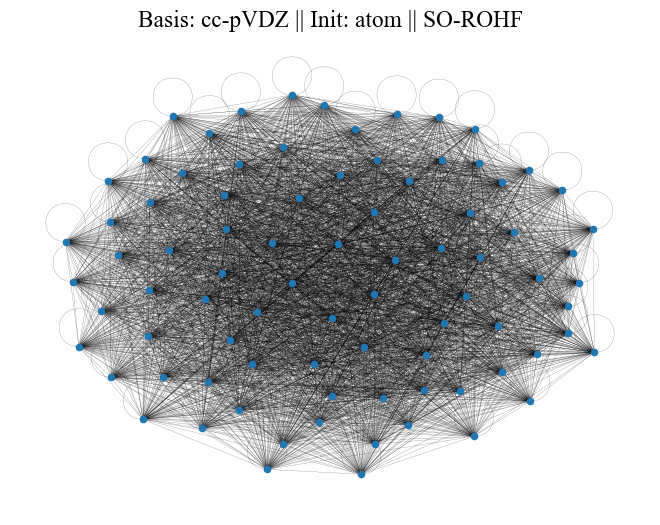

In [21]:
### VIEW QUBO GRAPH if desired:
import networkx as nx

G_qubo = nx.from_numpy_array(Q_matrix)
nx.draw(G_qubo, 
        node_size=20, 
        width=0.1 # edge width size
        )

plt.title(f"Basis: {basis} || Init: {init_method} || {scf_method.upper()}")
plt.show()

In [23]:
print(energies_std_df.to_latex(index=True))

\begin{tabular}{llll}
\toprule
 & cc-pVDZ & cc-pVTZ & cc-pVQZ \\
\midrule
1e & (-224.00169, -223.88841) & (-224.05179, -224.05179) & (-224.21012, -224.21012) \\
atom & (-223.92771, -223.85721) & (-223.97658, -223.91233) & (-223.99071, -223.92923) \\
huckel & (-224.13916, -224.13916) & (-224.19363, -224.19363) & (-224.21012, -224.21012) \\
minao & (-223.92771, -223.85721) & (-223.97658, -223.91233) & (-223.99071, -223.92923) \\
sap & (-224.00169, -223.88841) & (-224.04739, -223.94295) & (-224.06144, -223.99572) \\
vsap & (-223.92771, -223.85721) & (-223.97658, -223.91233) & (-223.99071, -223.92923) \\
\bottomrule
\end{tabular}



In [25]:
print(stability_std_df.to_latex(index=True))

\begin{tabular}{llll}
\toprule
 & cc-pVDZ & cc-pVTZ & cc-pVQZ \\
\midrule
1e & (True, False) & (True, False) & (True, True) \\
atom & (True, False) & (True, False) & (True, False) \\
huckel & (True, True) & (True, True) & (True, True) \\
minao & (True, False) & (True, False) & (True, False) \\
sap & (True, False) & (True, False) & (True, False) \\
vsap & (True, False) & (True, False) & (True, False) \\
\bottomrule
\end{tabular}



In [28]:
print(energies_so_df.to_latex(index=True))

\begin{tabular}{llll}
\toprule
 & cc-pVDZ & cc-pVTZ & cc-pVQZ \\
\midrule
1e & (-224.06688, -223.82783) & (-224.19363, -224.19363) & (-224.0023, -222.21971) \\
atom & (-223.97525, -223.82995) & (-224.11787, -223.88555) & (-224.13202, -223.90338) \\
huckel & (-224.13916, -224.13916) & (-224.19363, -224.19363) & (-224.21012, -224.21012) \\
minao & (-223.97525, -223.82995) & (-224.11787, -223.88555) & (-224.13202, -223.90338) \\
sap & (-224.07051, -224.07051) & (-224.19107, -224.19107) & (-224.20713, -224.20713) \\
vsap & (-223.97525, -223.82995) & (-224.11787, -223.88555) & (-224.13202, -223.90338) \\
\bottomrule
\end{tabular}



In [29]:
print(stability_so_df.to_latex(index=True))

\begin{tabular}{llll}
\toprule
 & cc-pVDZ & cc-pVTZ & cc-pVQZ \\
\midrule
1e & (True, False) & (True, True) & (True, False) \\
atom & (True, False) & (True, False) & (True, False) \\
huckel & (True, True) & (True, True) & (True, True) \\
minao & (True, False) & (True, False) & (True, False) \\
sap & (True, False) & (True, True) & (True, True) \\
vsap & (True, False) & (True, False) & (True, False) \\
\bottomrule
\end{tabular}

